# Aditya-L1 Solar Flare **Forecast** — 15-minute early warning on a live stream

**Question answered:** *Will the nowcast confirm a flare in the next 15 minutes?*

```
y(t) = 1   if the nowcast engine will raise a flare alarm (peak ≥ C1.0, or ≥ M1.0 for the major-flare model) in (t, t + 15 min]
```
Scored only at times when **no flare is in progress** (nowcast state QUIET or DECAY): during a flare the nowcast already knows.

### Why the original forecasting notebook had to be rebuilt
An audit of `model.ipynb` found problems that make its headline numbers (100 % TPR, 11.3 min warning) unreliable:

| # | Original | Effect | Here |
|---|---|---|---|
| 1 | Flare label = `counts > mean + 5·std` over the **whole** dataset | test statistics leak into labels; only huge spikes count | labels from the causal nowcast catalogue (validated vs NOAA) |
| 2 | every threshold re-crossing = new "flare" | one flare counted several times, later fragments "predicted" by alerts fired during the first | one flare = one nowcast event |
| 3 | lead time measured to the **peak** | inflates warning by the flare's own rise time | lead reported vs nowcast alarm, vs physical start, vs peak — separately |
| 4 | rows during flares scored | "predicting" flares already under way | only QUIET/DECAY rows are eligible |
| 5 | LightGBM `predict()` (0/1) averaged with probabilities | broken ensemble | all members contribute probabilities |
| 6 | 900-**row** windows, NaN → 0 | windows silently span gaps (SoLEXS is 13 % missing) | minute-based windows on a gap-aware grid |
| 7 | StandardScaler + PCA before trees | no benefit, hides physics | raw features + importances |
| 8 | one 70/15/15 split, 25 test events | no uncertainty; validation caught 19-22 while test "caught 25/25" | monthly walk-forward retraining over 8 months, ~700 test flares |

The honest numbers below are lower — and they are the ones an operator can rely on.

In [1]:
import sys, json, time, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = Path.cwd().parent                       # notebooks/ -> repository root
sys.path.insert(0, str(ROOT))
from l1_forecast import *
from l1_nowcast import *
from l1_nowcast.detector import FLARE, DECAY

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

DATA = ROOT / "data" / "goes"
OUT = ROOT / "outputs" / "forecast"; OUT.mkdir(parents=True, exist_ok=True)
FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)

H = 15                                         # forecast horizon, minutes
TARGETS = {"C1": "C1.0", "M1": "M1.0"}
TRAIN_FROM = "2026-01-01"
DEV = ("2026-03-01", "2026-07-01")             # out-of-sample months used to choose calibration + alert rule
TEST = ("2026-07-01", "2026-10-28")            # out-of-sample months used only for the final report
RUN_LIVE = True
SOLEXS_CSV = None   # Team Phoenix exports, for section 9
HEL1OS_CSV = None

## 1. Data and the nowcast catalogue that defines the labels

In [2]:
if not (DATA / "avg1m").exists():
    import datetime as dt
    print(download_goes_archive(DATA, dt.date(2026, 1, 1), dt.date(2026, 10, 27)))
xrs = load_goes_avg1m(DATA / "avg1m")
cfg_path = ROOT / "outputs" / "nowcast" / "nowcast_config.json"
if cfg_path.exists():
    CHANNELS = [ChannelConfig(**c) for c in json.loads(cfg_path.read_text())["channels"]]
    print("nowcast config: tuned values from nowcast.ipynb")
else:
    CHANNELS = goes_channels()
    print("nowcast config: library defaults")
t0 = time.time()
nc = run_batch(xrs, CHANNELS, cadence_s=60)
print(f"nowcast over {len(xrs):,} minutes in {time.time()-t0:.0f}s")
f = records_to_frame(nc.records, ["xrsb", "xrsa"])
X = build_features(f, "xrsb", "xrsa", step_min=1.0, absolute=True)
eligible = eligible_mask(f, "xrsb") & horizon_covered(f.index, f.index.max(), H)
print(f"feature matrix {X.shape}; eligible rows {eligible.mean():.1%}")
for name, mc in TARGETS.items():
    q = qualifying_events(nc.events, "xrsb", mc)
    y = make_targets(f.index, q["detect_time"], H)
    print(f"  target {name} (>= {mc}): {len(q):,} flares, positive rate on eligible rows {y[eligible].mean():.2%}")

nowcast config: tuned values from nowcast.ipynb


nowcast over 432,000 minutes in 27s


feature matrix (432000, 40); eligible rows 88.6%
  target C1 (>= C1.0): 1,712 flares, positive rate on eligible rows 6.46%
  target M1 (>= M1.0): 219 flares, positive rate on eligible rows 0.81%


### Features (40, all causal; minute-based windows on a gap-aware grid)
| group | features | physics |
|---|---|---|
| excess over nowcast background | `p_exc`, `p_exc_max{30,60,180,360,1440}`, `p_exc_d3` | how disturbed the corona is now / recently |
| growth | `p_d{1,2,3,5,10,15,30}`, `p_above_min{10,30}`, `p_rise_run` | early rise of a flare (gradual pre-flare brightening) |
| variability | `p_vol{10,30,60}` | small-scale activity / micro-flaring |
| secondary channel & ratio | `s_exc`, `s_d*`, `tr`, `tr_d*`, `tr_dev120` | XRS-A/XRS-B ratio ≈ plasma temperature: pre-flare heating |
| flaring history | `onsets_{6,24}h`, `min_since_onset`, `min_since_end`, `in_decay` | active regions flare in clusters |
| absolute level | `p_level`, `b_level`, `p_max1440` | overall activity of the disk (switch off for cross-instrument transfer) |
| data quality | `valid_frac60` | gaps |

In [3]:
print(list(X.columns))
# Causality check: scrambling the future must not change any past feature value
cut = len(f) // 2
f2 = f.copy(); f2.iloc[cut:] = f2.iloc[cut:].sample(frac=1.0, random_state=0).to_numpy()
assert build_features(f2, "xrsb", "xrsa").iloc[:cut].equals(X.iloc[:cut]), "feature leak!"
print("causality check passed")

['p_exc', 'p_d1', 'p_d2', 'p_d3', 'p_d5', 'p_d10', 'p_d15', 'p_d30', 'p_exc_max30', 'p_exc_max60', 'p_exc_max180', 'p_exc_max360', 'p_exc_max1440', 'p_vol10', 'p_vol30', 'p_vol60', 'p_above_min10', 'p_above_min30', 'p_rise_run', 'p_exc_d3', 's_exc', 's_d1', 's_d3', 's_d5', 's_d10', 'tr', 'tr_d1', 'tr_d3', 'tr_d5', 'tr_d10', 'tr_dev120', 'in_decay', 'onsets_6h', 'onsets_24h', 'min_since_onset', 'min_since_end', 'valid_frac60', 'p_level', 'b_level', 'p_max1440']


causality check passed


## 2. Walk-forward training, calibration, alert tuning
For each month from March to October a fresh LightGBM + XGBoost ensemble is trained on everything up to one day before the month
and predicts that month. **Dev** months (Mar–Jun) are used to fit the isotonic probability calibration and choose the alert rule
(threshold × persistence, maximising event CSI). **Test** months (Jul–Oct) are scored once with those choices frozen.

Baselines, trained the same way: **climatology** (constant rate), **activity logistic regression** (flare history + background level only),
and a **rise rule** (alert when XRS-B has grown by a tuned amount over 3 min — no machine learning).

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ACTIVITY = ["onsets_6h", "onsets_24h", "min_since_onset", "min_since_end", "p_level", "b_level", "p_exc", "p_exc_max360"]
in_ = lambda idx, rng: (idx >= pd.Timestamp(rng[0])) & (idx < pd.Timestamp(rng[1]))

def walk_forward_logistic(X, y, mask, starts, end):
    oos = pd.Series(np.nan, index=X.index)
    bounds = list(starts) + [end + pd.Timedelta("1min")]
    Xa = X[ACTIVITY].fillna(X[ACTIVITY].median())
    for i, t0 in enumerate(starts):
        tr = mask & (X.index < t0 - pd.Timedelta("1D")); te = (X.index >= t0) & (X.index < bounds[i + 1])
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)).fit(Xa[tr], y[tr])
        oos[te] = m.predict_proba(Xa[te])[:, 1]
    return oos

def run_target(name, min_class, Xmat, verbose=True):
    q = qualifying_events(nc.events, "xrsb", min_class)
    y = make_targets(f.index, q["detect_time"], H)
    starts = month_starts(DEV[0], f.index.max())
    t0 = time.time()
    oos_raw, folds = walk_forward(Xmat, y, eligible, starts, f.index.max(), lambda cols: FlareForecaster(cols), verbose=verbose)
    oos_log = walk_forward_logistic(Xmat if "p_level" in Xmat else X, y, eligible, starts, f.index.max())
    dev, test = eligible & in_(f.index, DEV), eligible & in_(f.index, TEST)
    clim = float(y[eligible & (f.index < pd.Timestamp(DEV[0]))].mean())

    calib = FlareForecaster(list(Xmat.columns)); calib.fit_calibration(oos_raw[dev].to_numpy(), y[dev].to_numpy())
    p = pd.Series(calib.calibrate(oos_raw.to_numpy()), index=f.index).where(eligible)

    prob_rows = {}
    for lab, sel in [("dev", dev), ("test", test)]:
        prob_rows[(lab, "GBM ensemble (calibrated)")] = probability_scores(y[sel], p[sel], clim)
        prob_rows[(lab, "activity logistic")] = probability_scores(y[sel], oos_log[sel], clim)
        prob_rows[(lab, "climatology")] = probability_scores(y[sel], np.full(sel.sum(), clim), clim)
    probs = pd.DataFrame(prob_rows).T

    q_dev = q[in_(pd.DatetimeIndex(q["detect_time"]), DEV)]
    q_test = q[in_(pd.DatetimeIndex(q["detect_time"]), TEST)]
    dmask = in_(f.index, DEV)
    tune = tune_alert_rule(p[dmask], eligible[dmask], q_dev, H)
    rule = tune.iloc[0]
    tmask = in_(f.index, TEST)
    alert_test = alert_series(p[tmask], eligible[tmask], rule.threshold, int(rule.m), int(rule.n))
    sc_test = score_events(alert_test, q_test, H)

    # rise-rule baseline: same tuning protocol on the 3-minute growth feature
    rise = Xmat["p_d3"].where(eligible) if "p_d3" in Xmat else X["p_d3"].where(eligible)
    tune_r = tune_alert_rule(rise[dmask], eligible[dmask], q_dev, H)
    rr = tune_r.iloc[0]
    sc_rise = score_events(alert_series(rise[tmask], eligible[tmask], rr.threshold, int(rr.m), int(rr.n)), q_test, H)

    ev = pd.DataFrame({"GBM forecast": sc_test.as_dict(), "rise rule (no ML)": sc_rise.as_dict()}).T
    if verbose:
        print(f"{name}: walk-forward + baselines in {time.time()-t0:.0f}s; alert rule: p >= {rule.threshold:.3f}, "
              f"{int(rule.m)} of {int(rule.n)} min")
    return dict(name=name, min_class=min_class, y=y, q=q, oos_raw=oos_raw, p=p, calib=calib, folds=folds,
                probs=probs, tune=tune, rule=rule, alert_test=alert_test, score=sc_test, events=ev, clim=clim,
                q_test=q_test, tmask=tmask)

R = {name: run_target(name, mc, X) for name, mc in TARGETS.items()}

  fold 2026-03: train=74,974 rows (pos 0.077)  test=37,882  8.5s


  fold 2026-04: train=112,717 rows (pos 0.070)  test=38,044  5.5s


  fold 2026-05: train=150,766 rows (pos 0.073)  test=40,942  5.6s


  fold 2026-06: train=191,700 rows (pos 0.073)  test=39,151  5.8s


  fold 2026-07: train=230,981 rows (pos 0.072)  test=37,220  6.9s


...

  fold 2026-07: train=230,981 rows (pos 0.008)  test=37,220  8.4s


  fold 2026-08: train=268,103 rows (pos 0.010)  test=41,134  5.6s


  fold 2026-09: train=309,319 rows (pos 0.009)  test=38,279  9.1s


  fold 2026-10: train=347,487 rows (pos 0.009)  test=33,908  9.7s


M1: walk-forward + baselines in 77s; alert rule: p >= 0.073, 3 of 5 min


## 3. Results — ≥C1.0 flares within 15 minutes

In [5]:
def show(r):
    print(f"== {r['name']} (peak >= {r['min_class']}), horizon {H} min ==")
    display(r["folds"])
    print("Sample-level skill (out-of-sample):"); display(r["probs"].round(4))
    print("Alert-rule tuning on dev (top 5):")
    display(r["tune"].head(5)[["threshold", "m", "n", "POD", "FAR(ratio)", "CSI", "false_alarms_per_day",
                              "lead_vs_nowcast_alarm_median_min", "lead_vs_start_median_min", "precursor_fraction"]].round(3))
    print("HELD-OUT TEST (Jul-Oct), event level:"); display(r["events"].round(3))
show(R["C1"])

== C1 (peak >= C1.0), horizon 15 min ==


,test_month,train_rows,train_pos_rate,test_rows,test_pos_rate,lgb_trees,seconds
0,2026-03,74974,0.077320,37882,0.053719,383,8.5
1,2026-04,112717,0.069998,38044,0.083456,118,5.5
2,2026-05,150766,0.073259,40942,0.072053,105,5.6
3,2026-06,191700,0.072754,39151,0.072310,82,5.8
4,2026-07,230981,0.072378,37220,0.076679,74,6.9
5,2026-08,268103,0.073214,41134,0.049521,93,7.7
6,2026-09,309319,0.070274,38279,0.025680,148,11.5
7,2026-10,347487,0.065513,33908,0.057420,109,10.6


Sample-level skill (out-of-sample):


n  pos_rate  ROC_AUC  PR_AUC   Brier  BSS_vs_climatology
dev  GBM ensemble (calibrated)  156019.0    0.0704   0.7511  0.2536  0.0590              0.1002
     activity logistic          156019.0    0.0704   0.6571  0.1181  0.0643              0.0185
     climatology                156019.0    0.0704   0.5000  0.0704  0.0655              0.0000
test GBM ensemble (calibrated)  150541.0    0.0520   0.7930  0.2556  0.0437              0.1240
     activity logistic          150541.0    0.0520   0.7127  0.1213  0.0478              0.0429
     climatology                150541.0    0.0520   0.5000  0.0520  0.0499              0.0000

Alert-rule tuning on dev (top 5):


,threshold,m,n,POD,FAR(ratio),CSI,false_alarms_per_day,lead_vs_nowcast_alarm_median_min,lead_vs_start_median_min,precursor_fraction
0,0.428,1,1,0.783,0.403,0.493,3.689,1.0,-5.0,0.092
1,0.362,1,1,0.820,0.446,0.470,4.664,2.0,-5.0,0.104
2,0.575,1,1,0.492,0.252,0.419,1.082,1.0,-5.0,0.061
3,0.294,1,1,0.891,0.558,0.378,8.484,2.0,-4.0,0.140
4,0.298,1,1,0.891,0.558,0.378,8.484,2.0,-4.0,0.140


HELD-OUT TEST (Jul-Oct), event level:


,flares,hits,misses,alert_episodes,false_alarms,POD,FAR(ratio),CSI,false_alarms_per_day,lead_vs_nowcast_alarm_median_min,lead_vs_start_median_min,lead_vs_peak_median_min,precursor_fraction
GBM forecast,542.0,359.0,183.0,603.0,220.0,0.662,0.365,0.471,1.849,1.0,-5.0,5.0,0.092
rise rule (no ML),542.0,352.0,190.0,808.0,446.0,0.649,0.552,0.356,3.748,1.0,-5.0,5.0,0.099


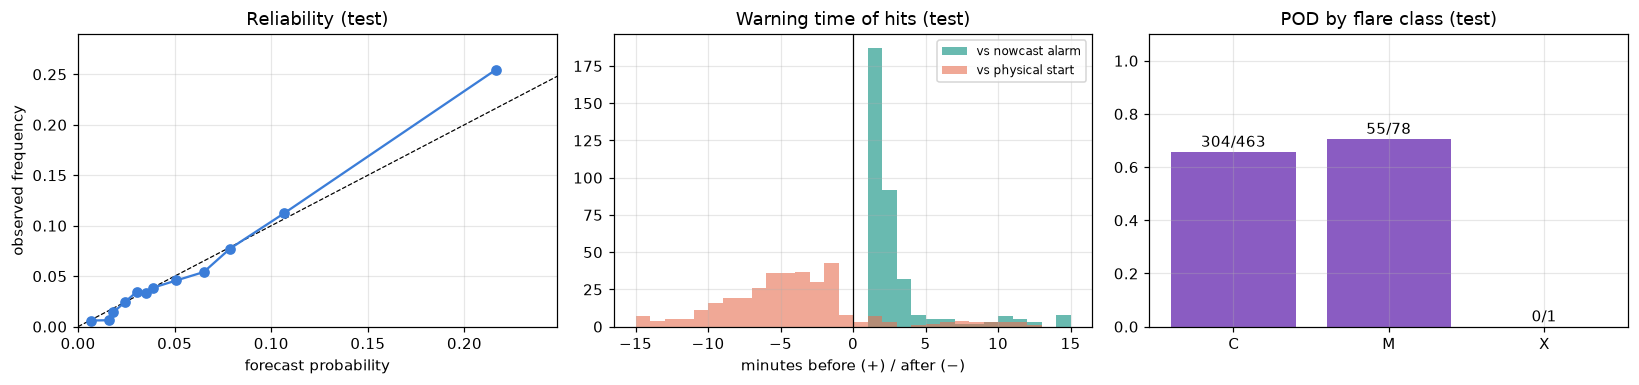

Month-by-month stability (test):


,flares,POD,FAR(ratio),CSI,false_alarms_per_day
month,,,,,
2026-07,198,0.778,0.311,0.562,2.452
2026-08,137,0.642,0.377,0.454,1.839
2026-09,68,0.235,0.500,0.190,0.533
2026-10,139,0.727,0.403,0.481,2.290


In [6]:
def diagnostics(r, fname):
    sc, al = r["score"], r["alert_test"]
    q = r["q_test"]
    q = q[(q["detect_time"] >= al.index.min()) & (q["detect_time"] <= al.index.max())].reset_index(drop=True)
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
    # reliability
    sel = eligible & in_(f.index, TEST)
    pp, yy = r["p"][sel].to_numpy(), r["y"][sel].to_numpy()
    bins = np.quantile(pp, np.linspace(0, 1, 16)); bins = np.unique(bins)
    k = np.clip(np.digitize(pp, bins[1:-1]), 0, len(bins) - 2)
    mp = [pp[k == i].mean() for i in range(len(bins) - 1)]; my = [yy[k == i].mean() for i in range(len(bins) - 1)]
    ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].plot(mp, my, "o-", color="#3b7dd8")
    ax[0].set(title="Reliability (test)", xlabel="forecast probability", ylabel="observed frequency",
              xlim=(0, max(mp) * 1.1 + 0.01), ylim=(0, max(max(my), max(mp)) * 1.1 + 0.01))
    # lead times
    bins_l = np.arange(-15, 16)
    ax[1].hist(sc.lead_detect, bins=bins_l, alpha=0.7, label="vs nowcast alarm", color="#2a9d8f")
    ax[1].hist(sc.lead_start, bins=bins_l, alpha=0.6, label="vs physical start", color="#e76f51")
    ax[1].axvline(0, color="k", lw=0.8); ax[1].legend(fontsize=8)
    ax[1].set(title="Warning time of hits (test)", xlabel="minutes before (+) / after (−)")
    # POD by flare class
    q["hit"] = sc.hit_flags; q["letter"] = q["flare_class"].str[0]
    pod = q.groupby("letter")["hit"].agg(["mean", "size"]).reindex(["C", "M", "X"]).dropna()
    ax[2].bar(pod.index, pod["mean"], color="#8a5cc2")
    for i, (L, rr) in enumerate(pod.iterrows()):
        ax[2].text(i, rr["mean"] + 0.02, f"{int(rr['mean'] * rr['size'])}/{int(rr['size'])}", ha="center")
    ax[2].set(title="POD by flare class (test)", ylim=(0, 1.1))
    plt.tight_layout(); plt.savefig(FIG / fname); plt.show()
    monthly = []
    for m0 in pd.date_range(TEST[0], TEST[1], freq="MS"):
        m1 = m0 + pd.offsets.MonthBegin(1)
        sm = score_events(r["alert_test"][(r["alert_test"].index >= m0) & (r["alert_test"].index < m1)],
                          r["q_test"], H, period=(m0, m1 - pd.Timedelta("1min")))
        monthly.append({"month": m0.strftime("%Y-%m"), **{k: sm.as_dict()[k] for k in ("flares", "POD", "FAR(ratio)", "CSI", "false_alarms_per_day")}})
    print("Month-by-month stability (test):"); display(pd.DataFrame(monthly).set_index("month").round(3))

diagnostics(R["C1"], "forecast_C1_diagnostics.png")

**Reading the ≥C1 result.** The forecaster genuinely beats climatology and the activity-only model, and gives a warning earlier than the
nowcast alarm for most flares it catches — but most of that warning is the **first minutes of the flare's own rise**, picked up before the
nowcast is confident (`lead_vs_start` is mostly negative; `precursor_fraction` is the share of warnings that came before the physical start).
That is the realistic physics of 1-minute soft X-ray data: there is little information about a C-flare 15 minutes before it begins.

## 4. Results — major flares (≥M1.0) within 15 minutes

== M1 (peak >= M1.0), horizon 15 min ==


,test_month,train_rows,train_pos_rate,test_rows,test_pos_rate,lgb_trees,seconds
0,2026-03,74974,0.015205,37882,0.002745,157,5.0
1,2026-04,112717,0.011036,38044,0.010672,69,4.1
2,2026-05,150766,0.010944,40942,0.002931,115,5.2
3,2026-06,191700,0.009233,39151,0.005440,65,5.3
4,2026-07,230981,0.008390,37220,0.020553,166,8.4
5,2026-08,268103,0.010250,41134,0.004157,33,5.6
6,2026-09,309319,0.009437,38279,0.001176,86,9.1
7,2026-10,347487,0.008530,33908,0.003981,88,9.7


Sample-level skill (out-of-sample):


n  pos_rate  ROC_AUC  PR_AUC   Brier  BSS_vs_climatology
dev  GBM ensemble (calibrated)  156019.0    0.0054   0.8234  0.0453  0.0052              0.0409
     activity logistic          156019.0    0.0054   0.7934  0.0290  0.0053              0.0282
     climatology                156019.0    0.0054   0.5000  0.0054  0.0055              0.0000
test GBM ensemble (calibrated)  150541.0    0.0074   0.8475  0.0923  0.0071              0.0477
     activity logistic          150541.0    0.0074   0.8678  0.0643  0.0072              0.0324
     climatology                150541.0    0.0074   0.5000  0.0074  0.0074              0.0000

Alert-rule tuning on dev (top 5):


,threshold,m,n,POD,FAR(ratio),CSI,false_alarms_per_day,lead_vs_nowcast_alarm_median_min,lead_vs_start_median_min,precursor_fraction
0,0.074,3,5,0.183,0.831,0.092,0.484,3.0,-5.0,0.455
1,0.074,3,3,0.167,0.853,0.081,0.525,2.5,-5.5,0.400
2,0.074,2,3,0.200,0.873,0.077,0.787,7.0,1.5,0.500
3,0.074,2,2,0.200,0.878,0.075,0.828,7.0,1.5,0.500
4,0.045,3,5,0.250,0.898,0.071,1.230,6.0,-2.0,0.467


HELD-OUT TEST (Jul-Oct), event level:


,flares,hits,misses,alert_episodes,false_alarms,POD,FAR(ratio),CSI,false_alarms_per_day,lead_vs_nowcast_alarm_median_min,lead_vs_start_median_min,lead_vs_peak_median_min,precursor_fraction
GBM forecast,79.0,35.0,44.0,178.0,139.0,0.443,0.781,0.161,1.168,13.0,4.0,16.0,0.571
rise rule (no ML),79.0,3.0,76.0,67.0,64.0,0.038,0.955,0.021,0.538,2.0,-5.0,27.0,0.333


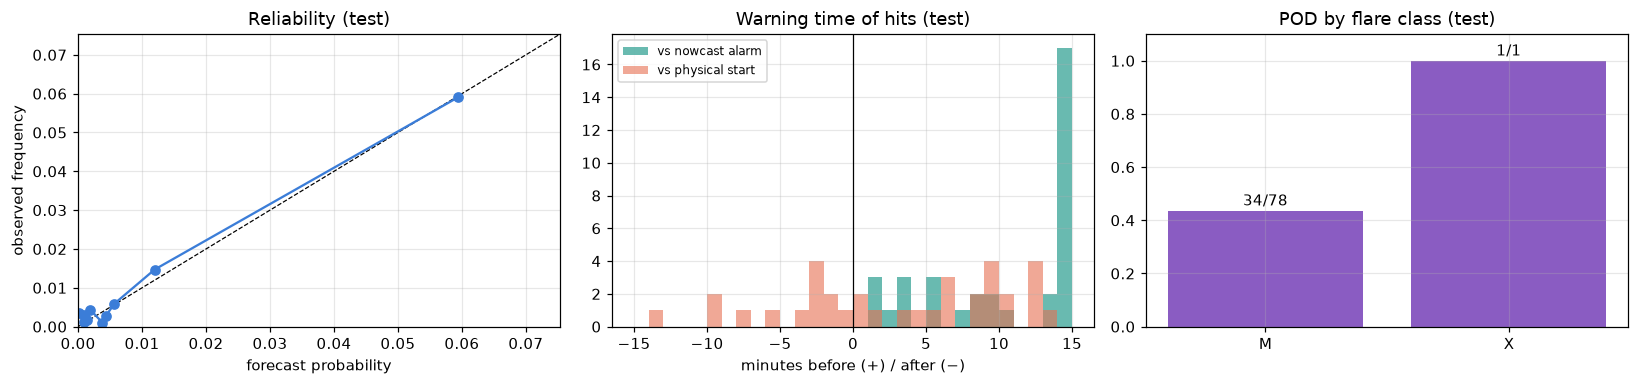

Month-by-month stability (test):


,flares,POD,FAR(ratio),CSI,false_alarms_per_day
month,,,,,
2026-07,55,0.618,0.778,0.181,4.290
2026-08,12,0.000,1.000,0.000,0.097
2026-09,3,0.000,0.000,0.000,0.000
2026-10,9,0.111,0.750,0.083,0.097


In [7]:
show(R["M1"])
diagnostics(R["M1"], "forecast_M1_diagnostics.png")

**Reading the ≥M1 result.** For major flares the warning is more often a true precursor (before the physical start), with a median
several minutes ahead of the nowcast alarm — but M-flares are rare, so at any useful detection rate a large share of alerts are false.
Treat the M1 probability as a **graded risk level** for operators, not a binary trigger.

## 5. One held-out major flare, minute by minute (out-of-sample probabilities)

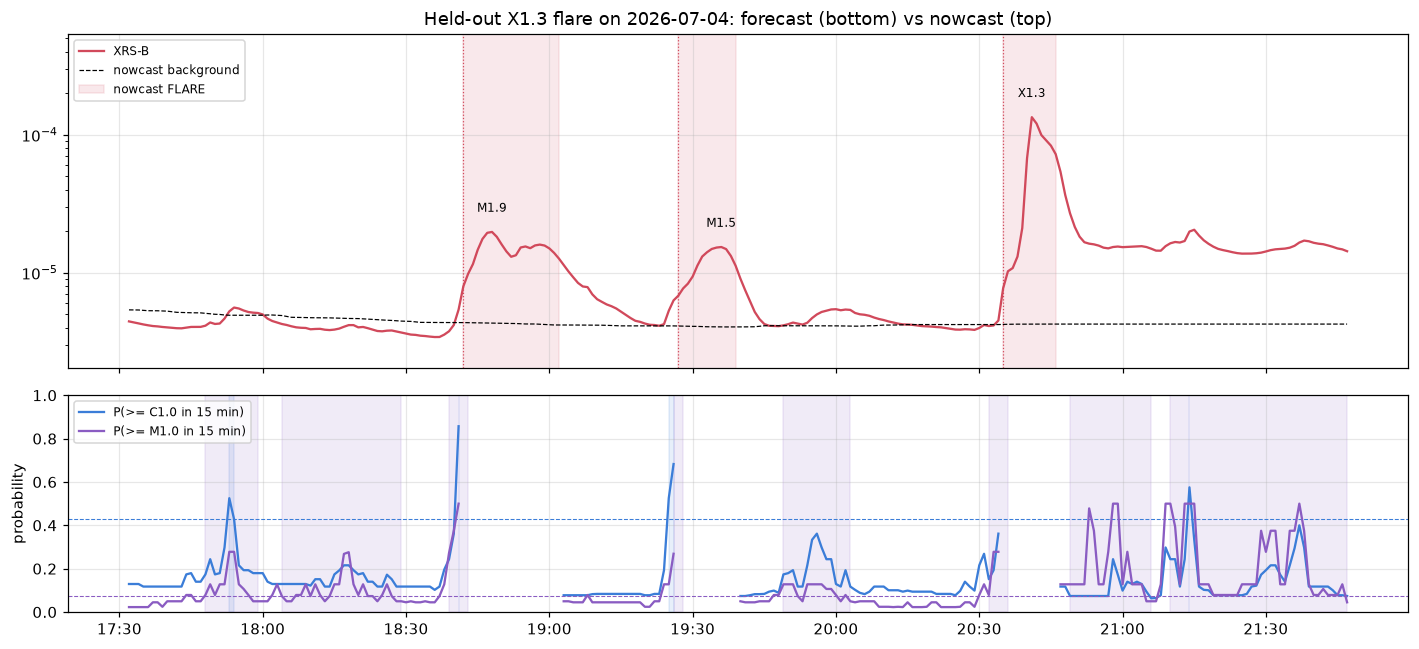

In [8]:
rM = R["M1"]; qt = rM["q_test"]
big = qt.loc[qt["peak"].idxmax()]
lo, hi = big["start"] - pd.Timedelta("3h"), big["end"] + pd.Timedelta("1h")
w = f.loc[lo:hi]
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1.3]})
ax[0].semilogy(w.index, w["xrsb_value"], color="#d1495b", label="XRS-B")
ax[0].semilogy(w.index, w["xrsb_background"], "k--", lw=0.8, label="nowcast background")
ax[0].fill_between(w.index, 1e-9, 1e-2, where=w["xrsb_state"] == FLARE, color="#d1495b", alpha=0.12, step="post", label="nowcast FLARE")
for _, e in R["C1"]["q"].iterrows():
    if lo <= e["detect_time"] <= hi:
        ax[0].axvline(e["detect_time"], color="#d1495b", lw=0.8, ls=":")
        ax[0].text(e["peak_time"], e["peak"] * 1.4, e["flare_class"], fontsize=8, ha="center")
ax[0].set_ylim(np.nanmin(w["xrsb_value"]) * 0.6, np.nanmax(w["xrsb_value"]) * 4); ax[0].legend(fontsize=8, loc="upper left")
ax[0].set_title(f"Held-out {big['flare_class']} flare on {big['peak_time']:%Y-%m-%d}: forecast (bottom) vs nowcast (top)")
for name, col in [("C1", "#3b7dd8"), ("M1", "#8a5cc2")]:
    r = R[name]; pw = r["p"].loc[lo:hi]
    ax[1].plot(pw.index, pw, color=col, label=f"P(>= {r['min_class']} in {H} min)")
    ax[1].axhline(r["rule"].threshold, color=col, ls="--", lw=0.7)
    al = alert_series(r["p"], eligible, r["rule"].threshold, int(r["rule"].m), int(r["rule"].n)).loc[lo:hi]
    ax[1].fill_between(al.index, 0, 1, where=al, color=col, alpha=0.12, step="post")
ax[1].set(ylim=(0, 1), ylabel="probability"); ax[1].legend(fontsize=8, loc="upper left")
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.tight_layout(); plt.savefig(FIG / "heldout_major_flare_timeline.png"); plt.show()

## 6. Production models (all data) + feature importance

saved models\C1  (alert: p >= 0.428, 1/1)


saved models\M1  (alert: p >= 0.073, 3/5)


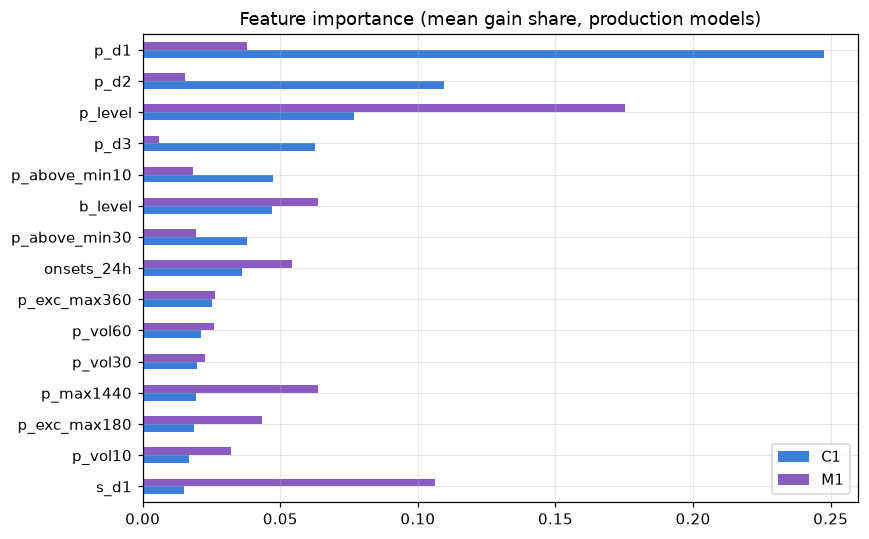

In [9]:
def train_final(name, Xmat, r, extra_tag=""):
    mdl = FlareForecaster(list(Xmat.columns)).fit(Xmat[eligible], r["y"][eligible])
    oos = r["oos_raw"]; ok = eligible & oos.notna()
    mdl.fit_calibration(oos[ok].to_numpy(), r["y"][ok].to_numpy())
    d = MODELS / f"{name}{extra_tag}"
    info = {"target": f"nowcast alarm for a flare >= {r['min_class']} within {H} min", "horizon_min": H,
            "min_class": r["min_class"], "trained_on": f"{f.index.min()} .. {f.index.max()} (GOES-19 XRS, 1 min)",
            "alert_rule": {"threshold": float(r["rule"].threshold), "m": int(r["rule"].m), "n": int(r["rule"].n)},
            "test_metrics_jul_oct": {k: (None if (isinstance(v, float) and math.isnan(v)) else v) for k, v in r["score"].as_dict().items()},
            "test_prob_scores": {k: float(v) for k, v in r["probs"].loc[("test", "GBM ensemble (calibrated)")].items()},
            "primary": "xrsb", "secondary": "xrsa"}
    mdl.save(d, extra=info)
    print(f"saved {d}  (alert: p >= {info['alert_rule']['threshold']:.3f}, {info['alert_rule']['m']}/{info['alert_rule']['n']})")
    return mdl

final = {name: train_final(name, X, R[name]) for name in TARGETS}
imp = pd.concat({n: m.feature_importance()["mean"] for n, m in final.items()}, axis=1).sort_values("C1", ascending=False)
ax = imp.head(15).iloc[::-1].plot.barh(figsize=(8, 5), color=["#3b7dd8", "#8a5cc2"])
ax.set_title("Feature importance (mean gain share, production models)"); plt.tight_layout(); plt.savefig(FIG / "feature_importance.png"); plt.show()

### Transfer model for Aditya-L1 (no absolute-level features)
SoLEXS reports counts, not W/m², so the absolute-level features don't transfer. This variant uses only background-relative and
temporal features (dimensionless in log space), so it can be applied to SoLEXS/HEL1OS on day one, and then retrained on Aditya-L1's own
nowcast catalogue with exactly the same code once enough data has been collected.

In [10]:
X_rel = X.drop(columns=["p_level", "b_level", "p_max1440"])
R["C1_transfer"] = run_target("C1_transfer", "C1.0", X_rel, verbose=False)
display(R["C1_transfer"]["events"].round(3))
final["C1_transfer"] = train_final("C1", X_rel, R["C1_transfer"], extra_tag="_transfer")

,flares,hits,misses,alert_episodes,false_alarms,POD,FAR(ratio),CSI,false_alarms_per_day,lead_vs_nowcast_alarm_median_min,lead_vs_start_median_min,lead_vs_peak_median_min,precursor_fraction
GBM forecast,542.0,374.0,168.0,699.0,302.0,0.690,0.432,0.443,2.538,1.0,-5.0,5.5,0.094
rise rule (no ML),542.0,352.0,190.0,808.0,446.0,0.649,0.552,0.356,3.748,1.0,-5.0,5.0,0.099


saved models\C1_transfer  (alert: p >= 0.430, 1/1)


## 7. Streaming: the live engine with the production models
`ForecastEngine` = `NowcastEngine` + rolling feature buffer + both models + alert managers, fed one sample at a time.
First: replay two days of archive through it and confirm it reproduces the batch probabilities exactly. Then: the real live feed.

In [11]:
def make_engine(model_names=("C1", "M1")):
    models = {}
    for n in model_names:
        m = FlareForecaster.load(MODELS / n)
        rule = m.saved["alert_rule"]
        models[n] = (m, AlertManager(rule["threshold"], rule["m"], rule["n"]))
    return ForecastEngine(NowcastEngine(CHANNELS, 60), models, "xrsb", "xrsa", horizon_min=H)

eng = make_engine()
replay = xrs["2026-08-01":"2026-08-03 23:59"]
recs, msgs = [], []
t0 = time.time()
for s in FrameSource(replay):
    rec, m = eng.update(s); recs.append(rec); msgs.extend(m)
el = time.time() - t0
stream = pd.DataFrame(recs).set_index("time")
print(f"{len(replay):,} live minutes processed in {el:.0f}s ({el/len(replay)*1000:.0f} ms per minute; real time allows 60,000 ms)")
# batch reference on the same 3 days: both start cold from the same first minute, so they must agree exactly
ncb = run_batch(replay, CHANNELS, 60)
fb = records_to_frame(ncb.records, ["xrsb", "xrsa"]); Xb = build_features(fb, "xrsb", "xrsa")
elb = eligible_mask(fb, "xrsb")
for n, (m, _) in eng.models.items():
    pb = pd.Series(m.predict_proba(Xb), index=Xb.index).where(elb)
    diff = (stream[f"p_{n}"] - pb).abs().max()
    print(f"  {n}: max |stream - batch| = {diff:.2e}")
print("messages:", pd.Series([m["type"] + (":" + m.get("target", "") if "target" in m else "") for m in msgs]).value_counts().to_dict())
stream.tail(3)

4,320 live minutes processed in 94s (22 ms per minute; real time allows 60,000 ms)


  C1: max |stream - batch| = 0.00e+00
  M1: max |stream - batch| = 0.00e+00
messages: {'onset': 29, 'end': 29, 'fused': 20, 'forecast_alert_on:C1': 12, 'forecast_alert_off:C1': 12}


,value,background,secondary_value,nowcast_state,horizon_min,p_C1,alert_C1,p_M1,alert_M1
time,,,,,,,,,
2026-08-03 23:57:00,5.632605e-07,5.463181e-07,1.708007e-08,QUIET,15,0.015579,False,0.001461,False
2026-08-03 23:58:00,5.685579e-07,5.463702e-07,1.549255e-08,QUIET,15,0.022699,False,0.001461,False
2026-08-03 23:59:00,5.712627e-07,5.468233e-07,1.432768e-08,QUIET,15,0.015897,False,0.001461,False


In [12]:
if RUN_LIVE:
    live = make_engine()
    src = GOESLiveSource(poll_s=60, backfill="3-day", max_polls=2, on_error=lambda e: print("feed error:", e))
    last, n, alerts = None, 0, []
    t0 = time.time()
    for s in src:
        rec, m = live.update(s); last = rec; n += 1
        alerts += [x for x in m if x["type"].startswith("forecast_alert")]
    print(f"live: {n} minutes up to {last['time']} UTC (processed in {time.time()-t0:.0f}s)")
    print(f"  XRS-B {last['value']:.2e} W/m² ({goes_class(last['value'])}-level) | nowcast: {last['nowcast_state']}")
    for name in ("C1", "M1"):
        p = last[f"p_{name}"]
        print(f"  P(flare >= {TARGETS[name]} in next {H} min) = {p:.1%}" if np.isfinite(p) else f"  {name}: flare in progress",
              "| ALERT" if last[f"alert_{name}"] else "")
    print("forecast alerts in the last 3 days:", len([a for a in alerts if a["type"] == "forecast_alert_on"]))
else:
    print("RUN_LIVE is False - skipped")

live: 4321 minutes up to 2026-10-28 19:11:00 UTC (processed in 148s)
  XRS-B 4.11e-07 W/m² (B4.1-level) | nowcast: QUIET
  P(flare >= C1.0 in next 15 min) = 2.3% 
  P(flare >= M1.0 in next 15 min) = 0.0% 
forecast alerts in the last 3 days: 2


## 8. Aditya-L1: 1-second SoLEXS + HEL1OS input
The forecast runs at a 1-minute cadence on top of the 1-second nowcast: `ForecastEngine(..., forecast_cadence_s=60)` aggregates the
nowcast records into minute bins (value/background mean, last state, any onset) — the identical reduction used for training
(`records_to_frame(..., cadence="60s")`). With `SOLEXS_CSV`/`HEL1OS_CSV` set, the real data are used; otherwise a synthetic day
(clearly labelled) demonstrates the plumbing with the transfer model.

In [13]:
m_tr = FlareForecaster.load(MODELS / "C1_transfer")
rule = m_tr.saved["alert_rule"]
if SOLEXS_CSV and HEL1OS_CSV:
    adi = align_frames(read_solexs_csv(SOLEXS_CSV), read_hel1os_csv(HEL1OS_CSV))[["solexs_counts", "hel1os_cdte"]]
    src = FrameSource(adi); label = "Aditya-L1 SoLEXS + HEL1OS"
else:
    rng = np.random.default_rng(3); n = 30 * 3600; sec = np.arange(n)
    soft = rng.poisson(9, n).astype(float); hard = rng.poisson(0.2, n).astype(float)
    for t0 in (26 * 3600, 28 * 3600):
        soft += np.where(sec >= t0, 700 * np.minimum((sec - t0) / 400, 1) * np.exp(-np.maximum(sec - t0 - 400, 0) / 700), 0)
        hard += np.where((sec >= t0 + 30) & (sec < t0 + 300), rng.poisson(30, n), 0)
    adi = pd.DataFrame({"solexs_counts": soft, "hel1os_cdte": hard}, index=pd.date_range("2026-03-30", periods=n, freq="1s"))
    src = FrameSource(adi); label = "SYNTHETIC 1 Hz stream (plumbing demo, not science)"
adi_eng = ForecastEngine(NowcastEngine(aditya_channels(), 1), {"C1": (m_tr, AlertManager(rule["threshold"], rule["m"], rule["n"]))},
                         "solexs_counts", "hel1os_cdte", forecast_cadence_s=60, horizon_min=H)
out, mm = [], []
t0 = time.time()
for s in src:
    rec, m = adi_eng.update(s); mm.extend(m)
    if rec is not None: out.append(rec)
o = pd.DataFrame(out).set_index("time")
print(f"{label}: {len(adi):,} one-second samples -> {len(o):,} minute forecasts in {time.time()-t0:.0f}s")
print("messages:", pd.Series([x["type"] for x in mm]).value_counts().to_dict())
o.loc[o["nowcast_state"].ne(o["nowcast_state"].shift()) | o["alert_C1"].ne(o["alert_C1"].shift())].tail(8)

SYNTHETIC 1 Hz stream (plumbing demo, not science): 108,000 one-second samples -> 1,799 minute forecasts in 36s
messages: {'onset': 9, 'end': 9, 'fused': 7}


,value,background,secondary_value,nowcast_state,horizon_min,p_C1,alert_C1
time,,,,,,,
2026-03-31 03:01:00,14.941016,8.900000,0.286667,FLARE,15,NaN,False
2026-03-31 03:02:00,14.079119,8.900000,0.313333,QUIET,15,0.013991,False
2026-03-31 03:03:00,14.070503,8.900000,0.076667,FLARE,15,NaN,False
2026-03-31 03:07:00,12.888650,8.900000,0.126667,QUIET,15,0.050894,False
2026-03-31 04:00:00,52.963736,9.701540,13.773333,FLARE,15,NaN,False
2026-03-31 04:14:00,369.322619,9.701526,0.153333,DECAY,15,0.021219,False
2026-03-31 04:57:00,17.174585,9.702347,0.236667,FLARE,15,NaN,False
2026-03-31 05:00:00,15.450307,9.713409,0.130000,QUIET,15,0.029608,False


## 9. Summary and comparison with the original notebook's claims

In [14]:
rows = {"original notebook (as claimed)": {"flares scored": 25, "POD": 1.00, "FAR(ratio)": 0.107, "CSI": 0.893, "median warning (min)": "11.3 (to peak)"}}
for name in ["C1", "M1", "C1_transfer"]:
    d = R[name]["score"].as_dict()
    rows[f"this work: >= {R[name]['min_class']}{' transfer' if 'transfer' in name else ''} (held-out Jul-Oct)"] = {
        "flares scored": d["flares"], "POD": d["POD"], "FAR(ratio)": d["FAR(ratio)"], "CSI": d["CSI"],
        "median warning (min)": f"{d['lead_vs_nowcast_alarm_median_min']:.1f} vs nowcast / {d['lead_vs_start_median_min']:.1f} vs start / {d['lead_vs_peak_median_min']:.1f} vs peak",
        "false alarms/day": round(d["false_alarms_per_day"], 2),
        "ROC AUC": round(R[name]["probs"].loc[("test", "GBM ensemble (calibrated)"), "ROC_AUC"], 3),
        "BSS": round(R[name]["probs"].loc[("test", "GBM ensemble (calibrated)"), "BSS_vs_climatology"], 3)}
comparison = pd.DataFrame(rows).T
comparison.to_csv(OUT / "comparison_with_original.csv")
for name in R:
    R[name]["events"].to_csv(OUT / f"test_events_{name}.csv"); R[name]["probs"].to_csv(OUT / f"test_prob_scores_{name}.csv")
    R[name]["folds"].to_csv(OUT / f"walk_forward_folds_{name}.csv", index=False)
comparison

,flares scored,POD,FAR(ratio),CSI,median warning (min),false alarms/day,ROC AUC,BSS
original notebook (as claimed),25,1.0,0.107,0.893,11.3 (to peak),NaN,NaN,NaN
this work: >= C1.0 (held-out Jul-Oct),542,0.662362,0.364842,0.471129,1.0 vs nowcast / -5.0 vs start / 5.0 vs peak,1.85,0.793,0.124
this work: >= M1.0 (held-out Jul-Oct),79,0.443038,0.780899,0.16055,13.0 vs nowcast / 4.0 vs start / 16.0 vs peak,1.17,0.848,0.048
this work: >= C1.0 transfer (held-out Jul-Oct),542,0.690037,0.432046,0.443128,1.0 vs nowcast / -5.0 vs start / 5.5 vs peak,2.54,0.771,0.108
